# Part III — PCA: what makes a good car?
**Method (session 9):** Principal Component Analysis.
**Why:** we track 7 statistics per team (points, top-10 rate, podiums, average finish, average grid, qualifying gap, mechanical failures). They overlap heavily. PCA turns them into a few independent axes, which we can read and plot.
**Answer in one sentence:** two axes are enough: **car performance** (77% of the information) and **reliability** (12%).

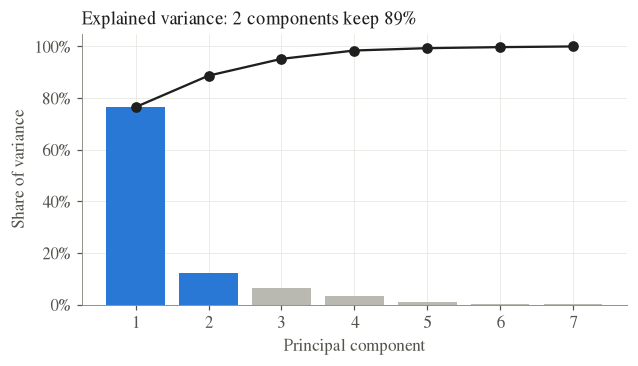

Explained variance: [76.5 12.2  6.5  3.2  0.9  0.4  0.3] %


In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
from f1duel.model import CarProfile
train = d[d.year <= 2024]
prof = CarProfile().fit(train)
ev = prof.pca.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.bar(range(1, 8), ev, color=[BLUE, BLUE] + [GREY] * 5); ax.plot(range(1, 8), np.cumsum(ev), 'o-', color=INK)
ax.set_xlabel('Principal component'); ax.set_ylabel('Share of variance'); ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
title(ax, 'Explained variance: 2 components keep 89%'); save(fig, '03_variance'); plt.show()
print('Explained variance:', (ev * 100).round(1), '%')

In [2]:
prof.loadings().round(2)

,PC1 car performance,PC2 reliability
team_points,0.41,-0.21
team_top10,0.40,-0.02
team_podium,0.37,-0.28
team_avg_finish,-0.42,-0.01
team_avg_grid,-0.41,0.05
team_quali_gap,-0.39,-0.06
team_mech_dnf,-0.20,-0.93


**Reading the loadings:**
- **PC1 = car performance.** Points, top-10 and podium rates load positively; average finish, average grid and qualifying gap load negatively (smaller is better). One number now summarises "how fast is this car".
- **PC2 = reliability.** Almost only the mechanical failure rate (oriented so that higher = fewer failures).

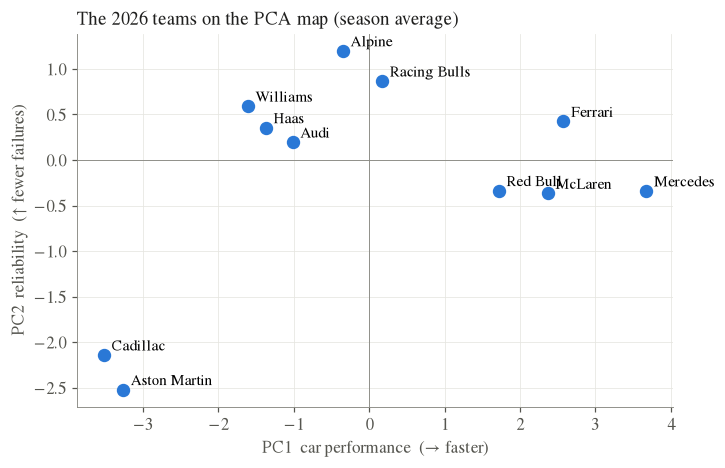

In [3]:
dd = prof.transform(d)
season = dd[dd.year == 2026].groupby('team_name')[['car_perf', 'car_rel']].mean()
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.scatter(season.car_perf, season.car_rel, s=60, color=BLUE)
for t, r in season.iterrows(): ax.annotate(t, (r.car_perf, r.car_rel), xytext=(5, 3), textcoords='offset points', fontsize=10)
ax.axhline(0, color=MUTED, lw=0.6); ax.axvline(0, color=MUTED, lw=0.6)
ax.set_xlabel('PC1  car performance  (→ faster)'); ax.set_ylabel('PC2  reliability  (↑ fewer failures)')
title(ax, 'The 2026 teams on the PCA map (season average)'); save(fig, '03_map_2026'); plt.show()

**Limitation:** PCA is linear and the axes are fitted on 2010–2024. It works because team strength really is mostly one-dimensional. In later parts, the PCA is re-fitted before every prediction, using only past races.